# quick exploration of cell tracks dataframes, anvil/cell features

In [1]:

import numpy as np
import xarray as xr
import os
import pandas as pd

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

import os 

In [2]:
inputdir = Path("../output/final_dataframes")

models = ["ICON","OBS"]
timeperiods = ["JUNE","DECEMBER"]


savedir = Path("../output/eval/tryoutsdirt")
savedir.mkdir(parents=True, exist_ok=True)

In [17]:
cellfeatures = {}
anvilfeatures = {}
cells = {}
domain = {}

for model in models:
    cellfeatures[model] = {}
    anvilfeatures[model] = {}
    cells[model] = {}
    domain[model] ={}

    for timeperiod in timeperiods:

        cellfeatures[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"cell_features_{model}_{timeperiod}.h5"),
            key="table"
        )

        anvilfeatures[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"anvil_features_{model}_{timeperiod}.h5"),
            key="table"
        )

        cells[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"cell_tracks_{model}_{timeperiod}.h5"),
            key="table"
        )
        domain[model][timeperiod] = pd.read_hdf(
            os.path.join(inputdir, f"domain_{model}_{timeperiod}.h5"),
            key="table"
        )

# plotting functions

In [4]:
def quick_histograms(ds, vars_to_plot = None, vars_not_plot = ["track","time"], density = True, month = "JUNE",nbins = 60, use_log_bins = "default" ):
    if vars_to_plot is None:
        vars_to_plot = [
            var for var in ds["OBS"]["JUNE"].columns
            if var not in vars_not_plot
        ]
    
    n = len(vars_to_plot)
    ncols = 4
    nrows = int(np.ceil(n / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    
    for ax, var in zip(axes, vars_to_plot):
        obs_vals = ds["OBS"][month][var].dropna()
        icon_vals = ds["ICON"][month][var].dropna()

        # shared bin edges from the combined range of both datasets
        combined = pd.concat([obs_vals, icon_vals])

        use_log_bins = ("precip" in var.lower() or "rain" in var.lower())

        if use_log_bins:
            bins = np.logspace(np.log10(combined.min()), np.log10(combined.max()), nbins + 1)
        elif var == "n_sister_cells_max" or var=="n_sister_cells_mean" or  var == "n_sister_cells" or var == "n_children_anvil":
            bins = np.arange(combined.min(), combined.max() + 2) - 0.5           
        else:
            bins = np.linspace(combined.min(), combined.max(), nbins + 1)


        ax.hist(obs_vals, bins=bins, density=density, alpha=0.5, label="OBS", color="royalblue") # ave for anvils: #8a4a7d
        ax.hist(icon_vals, bins=bins, density=density, alpha=0.5, label="ICON", color="darkorange")

        ax.set_title(var)
        ax.set_yscale("log")
        if use_log_bins: 
            ax.set_xscale("log")
        ax.grid(False)
    # remove unused axes
    for ax in axes[len(vars_to_plot):]:
        fig.delaxes(ax)
    
    axes[0].legend()
    fig.tight_layout()
    sns.despine()
    return fig

def quick_boxplots(ds, vars_to_plot = None, vars_not_plot = ["track","time"], month = "JUNE"):
    if vars_to_plot is None:
        vars_to_plot = [
            var for var in ds["OBS"]["JUNE"].columns
            if var not in vars_not_plot]
    
    n = len(vars_to_plot)
    ncols = 4
    nrows = int(np.ceil(n / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows))
    axes = np.atleast_1d(axes).ravel()
    
    for ax, var in zip(axes, vars_to_plot):
        ax.boxplot(
            [
                ds["OBS"][month][var].dropna(),
                ds["ICON"][month][var].dropna(),
            ],
            tick_labels=["OBS", "ICON"],
        )
        ax.set_title(var)
    
    # remove unused axes
    for ax in axes[len(vars_to_plot):]:
        fig.delaxes(ax)
    
    fig.tight_layout()
    sns.despine()
    return fig

# cells 

In [5]:
cells["ICON"]["JUNE"].columns

Index(['track', 'mean_precip_cell_mean', 'max_precip_cell_max',
       'total_precip_cell_mean', 'rain_amount_cell_sum', 'lifetime_cell',
       'area_cell_mean', 'd_eq_cell_mean', 'd_eq_cell_max', 'velo_cell_mean',
       'n_sister_cells_max', 'n_sister_cells_mean',
       'min_dist_nonsister_cell_km_mean', 'min_dist_cell_km_mean',
       'PE_cell_mean', 'mean_precip_anvil_mean', 'rain_amount_anvil_sum',
       'mean_iwp_anvil_mean', 'max_iwp_anvil_max', 'total_iwp_anvil_mean',
       'iwp_amount_anvil_sum', 'area_anvil_mean', 'd_eq_anvil_mean',
       'd_eq_anvil_max', 'min_tb_anvil_min', 'n_children_anvil_mean', 'time'],
      dtype='object')

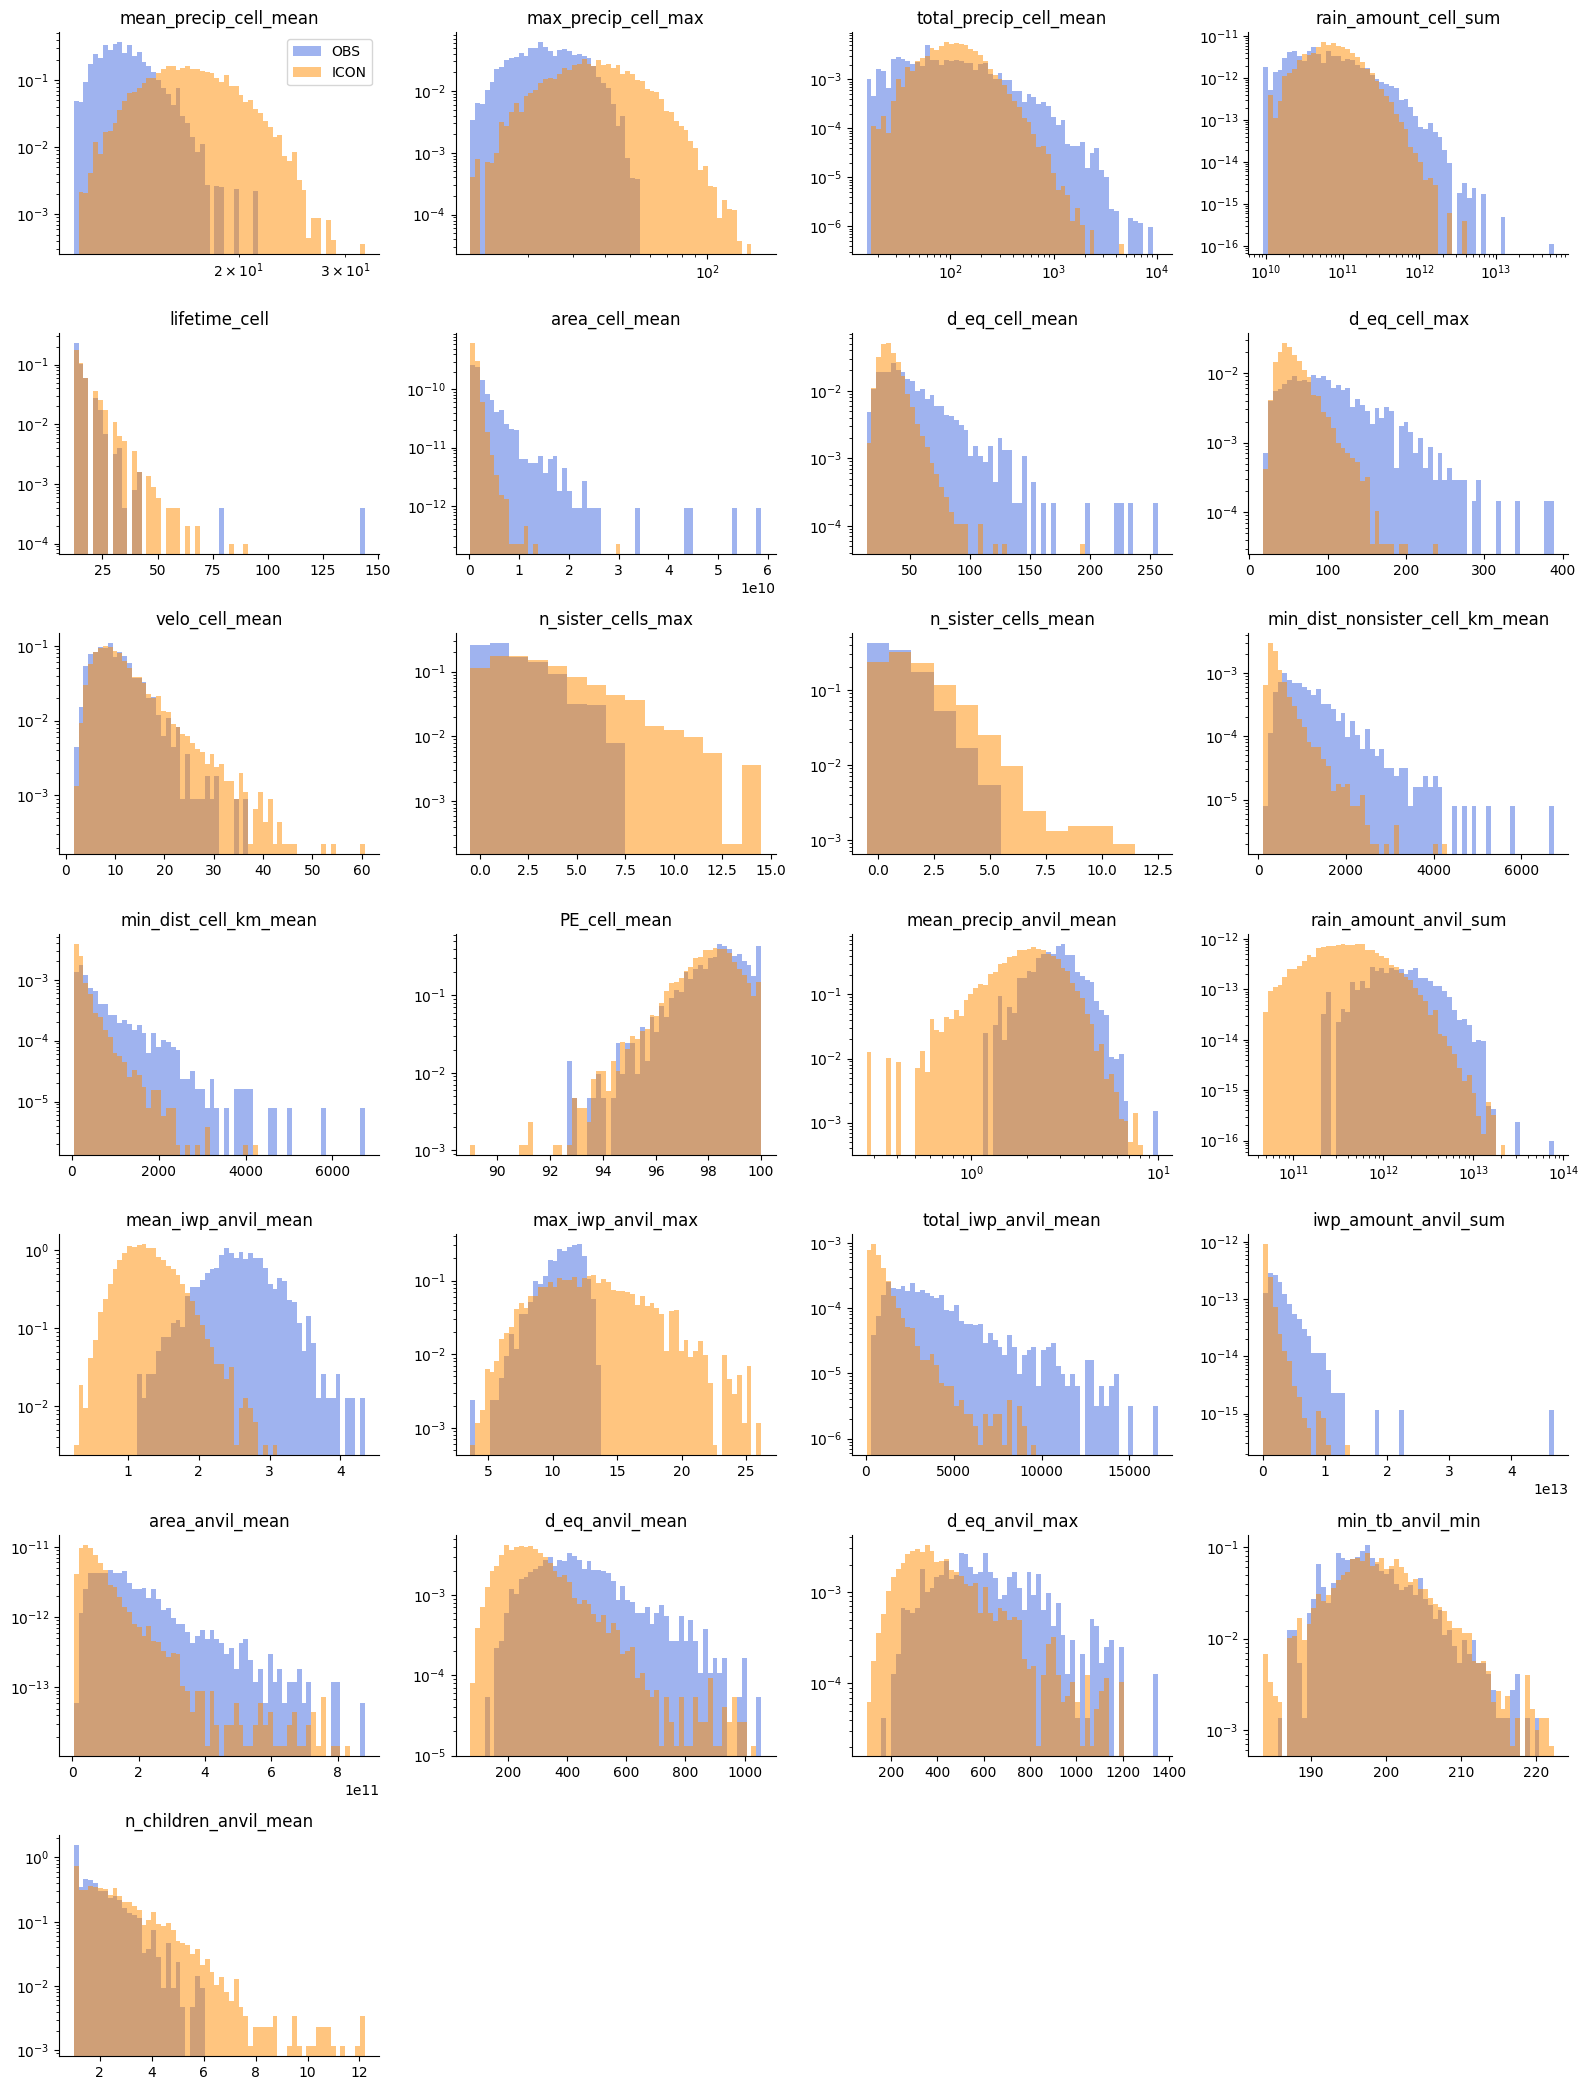

In [6]:
fig = quick_histograms(cells)

fig.savefig(os.path.join(savedir,"cellprops_hist.pdf"))
plt.show()

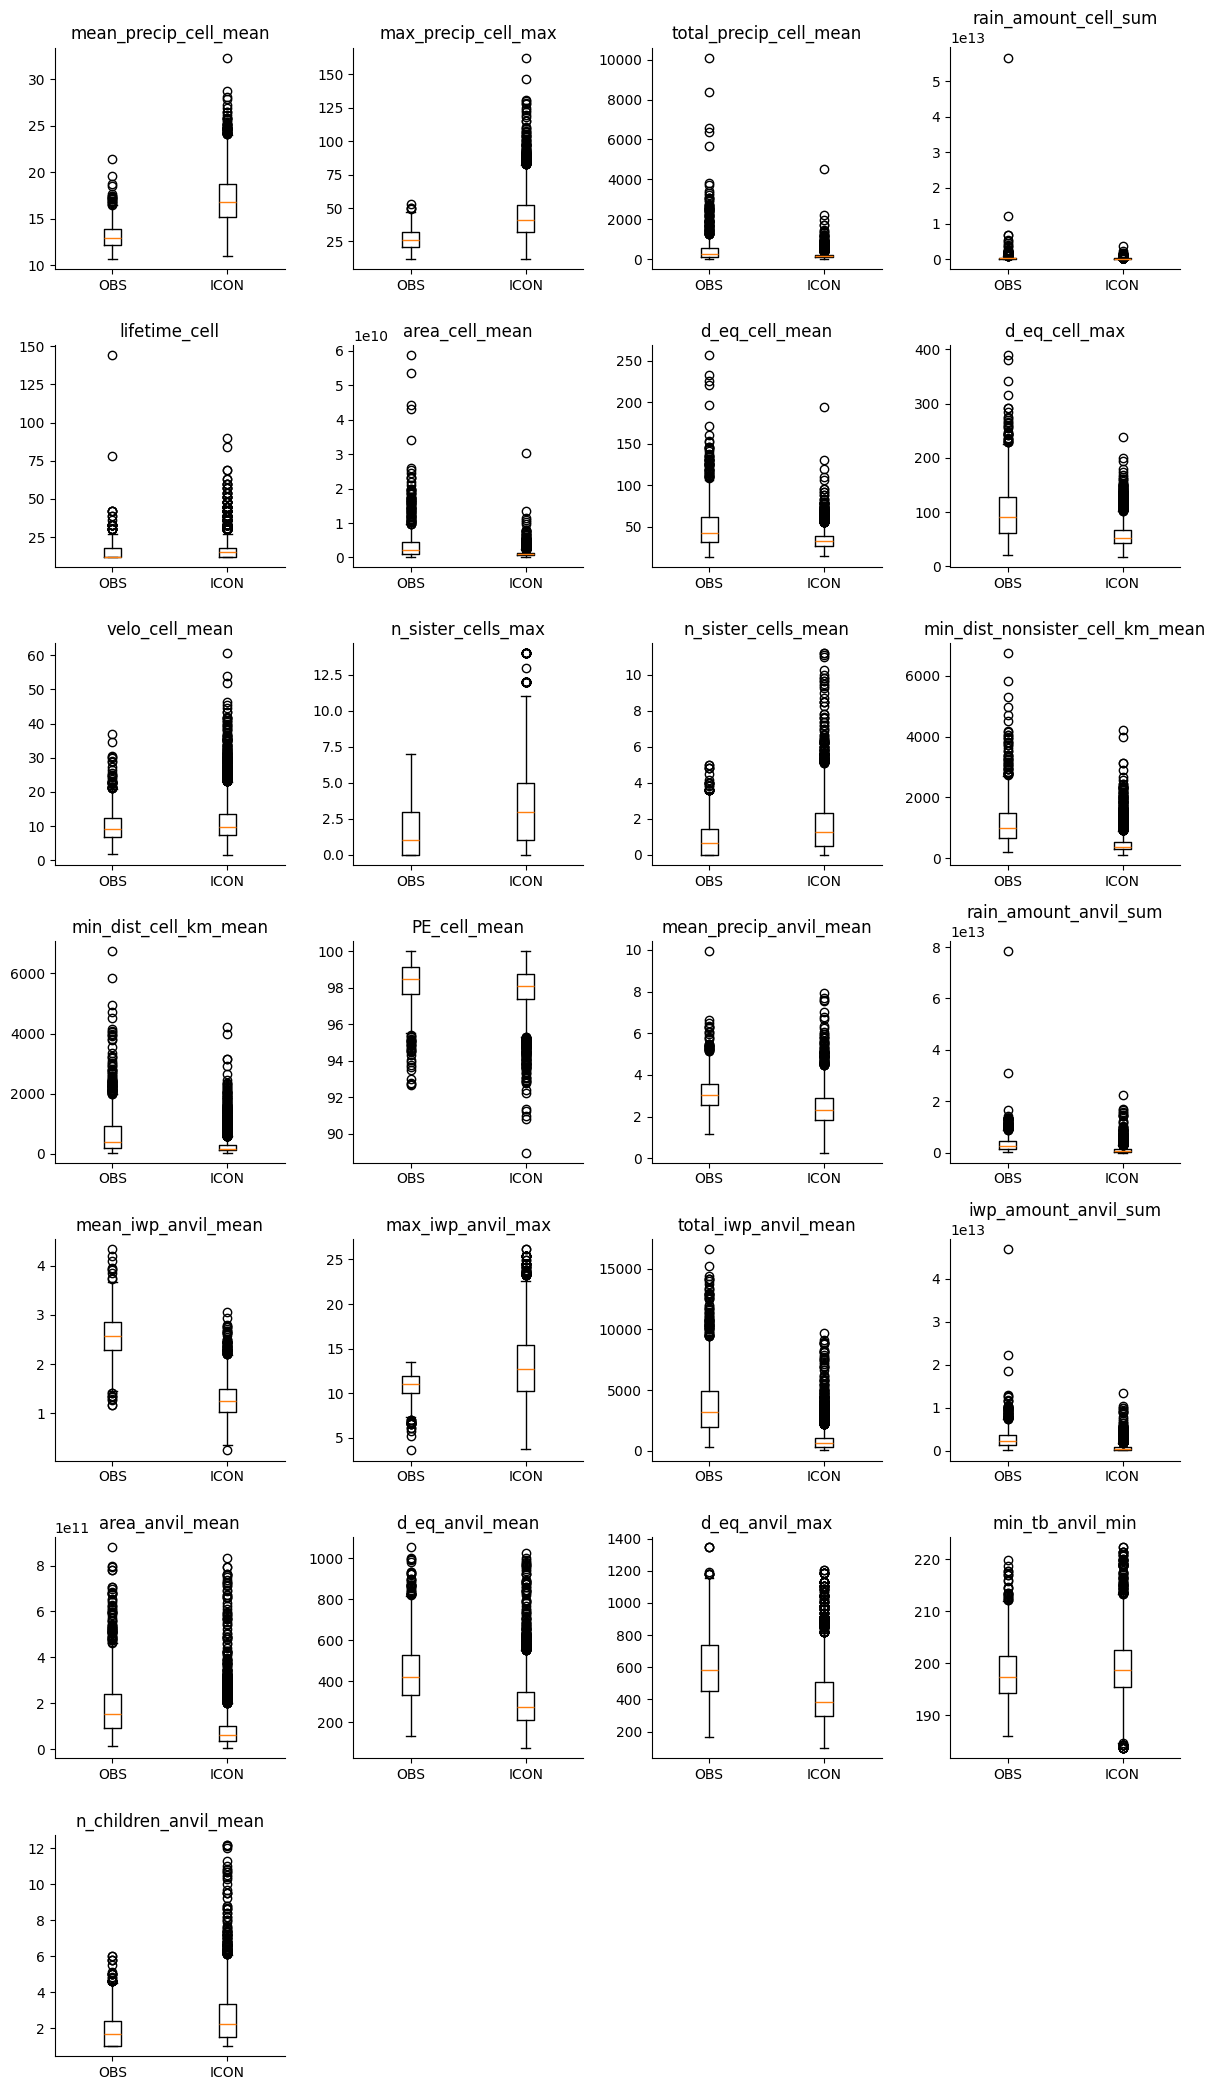

In [7]:
quick_boxplots(cells)
plt.show()

# Anvil fetaures

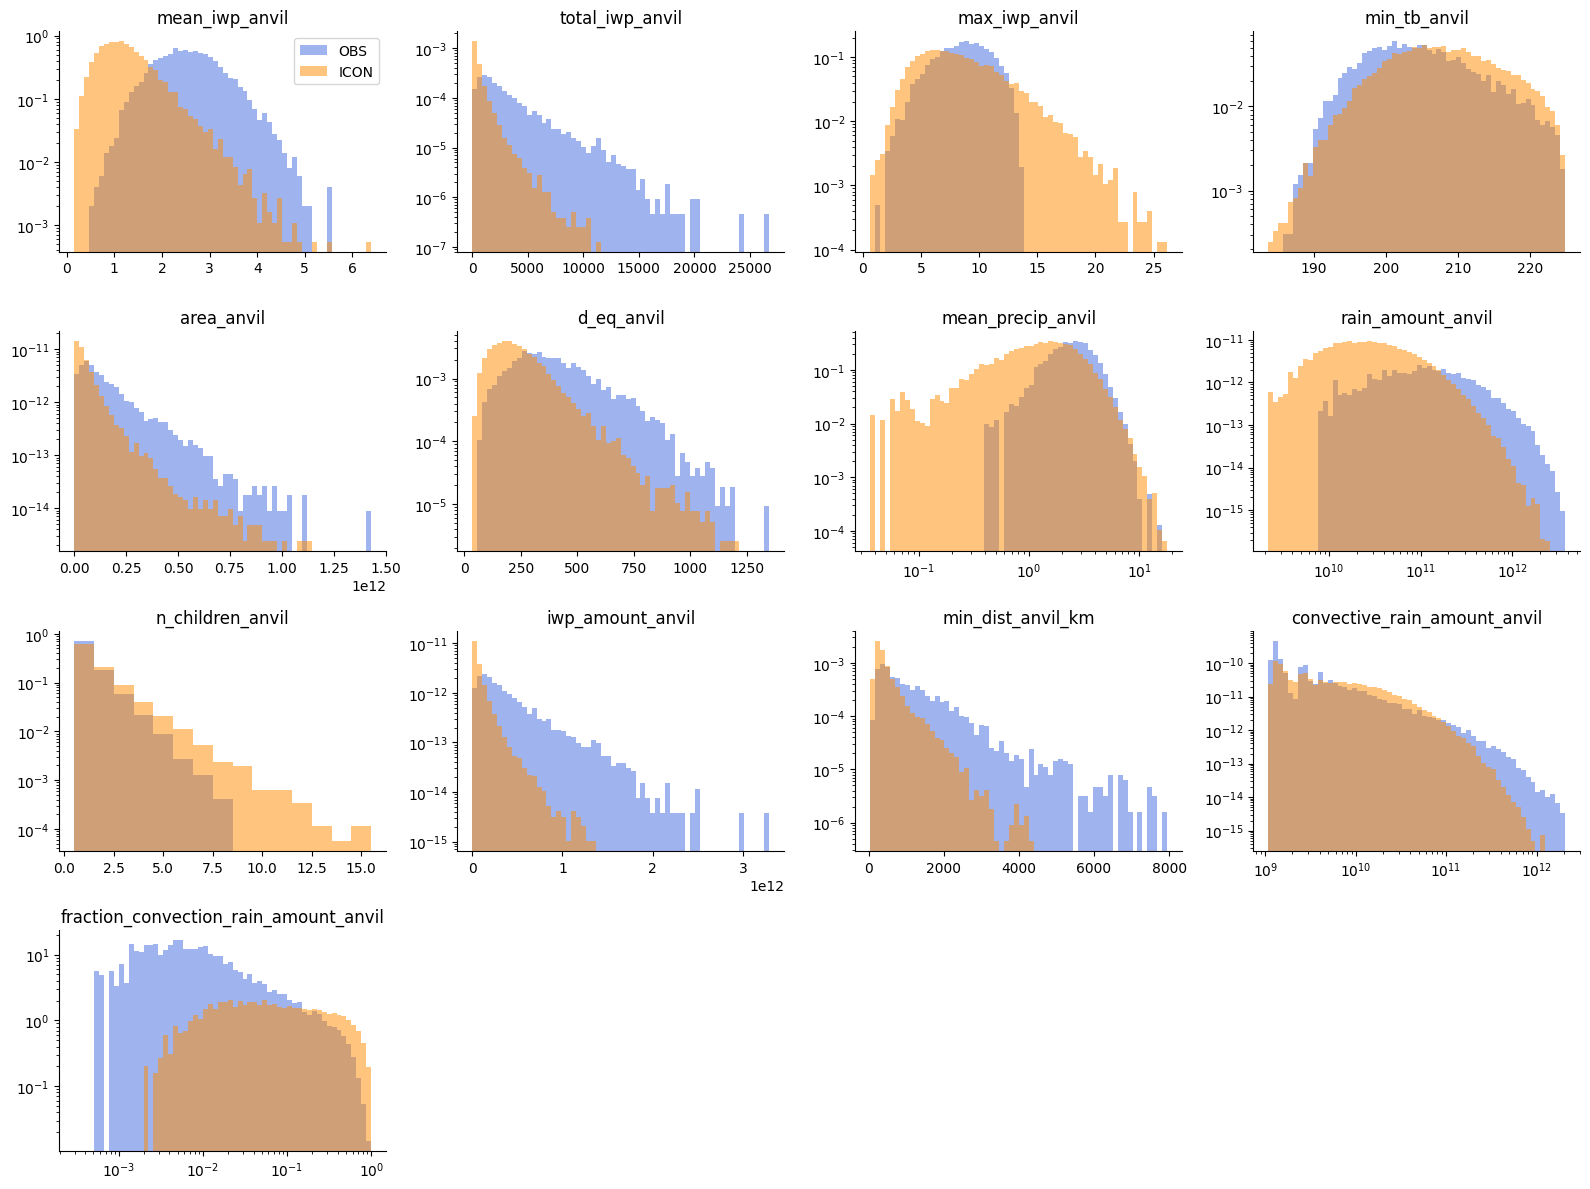

In [8]:
quick_histograms(anvilfeatures, vars_not_plot = ["time","num_anvil","feature_anvil"])
plt.savefig(os.path.join(savedir,"anvilfeatures_hist.pdf"))
plt.show()

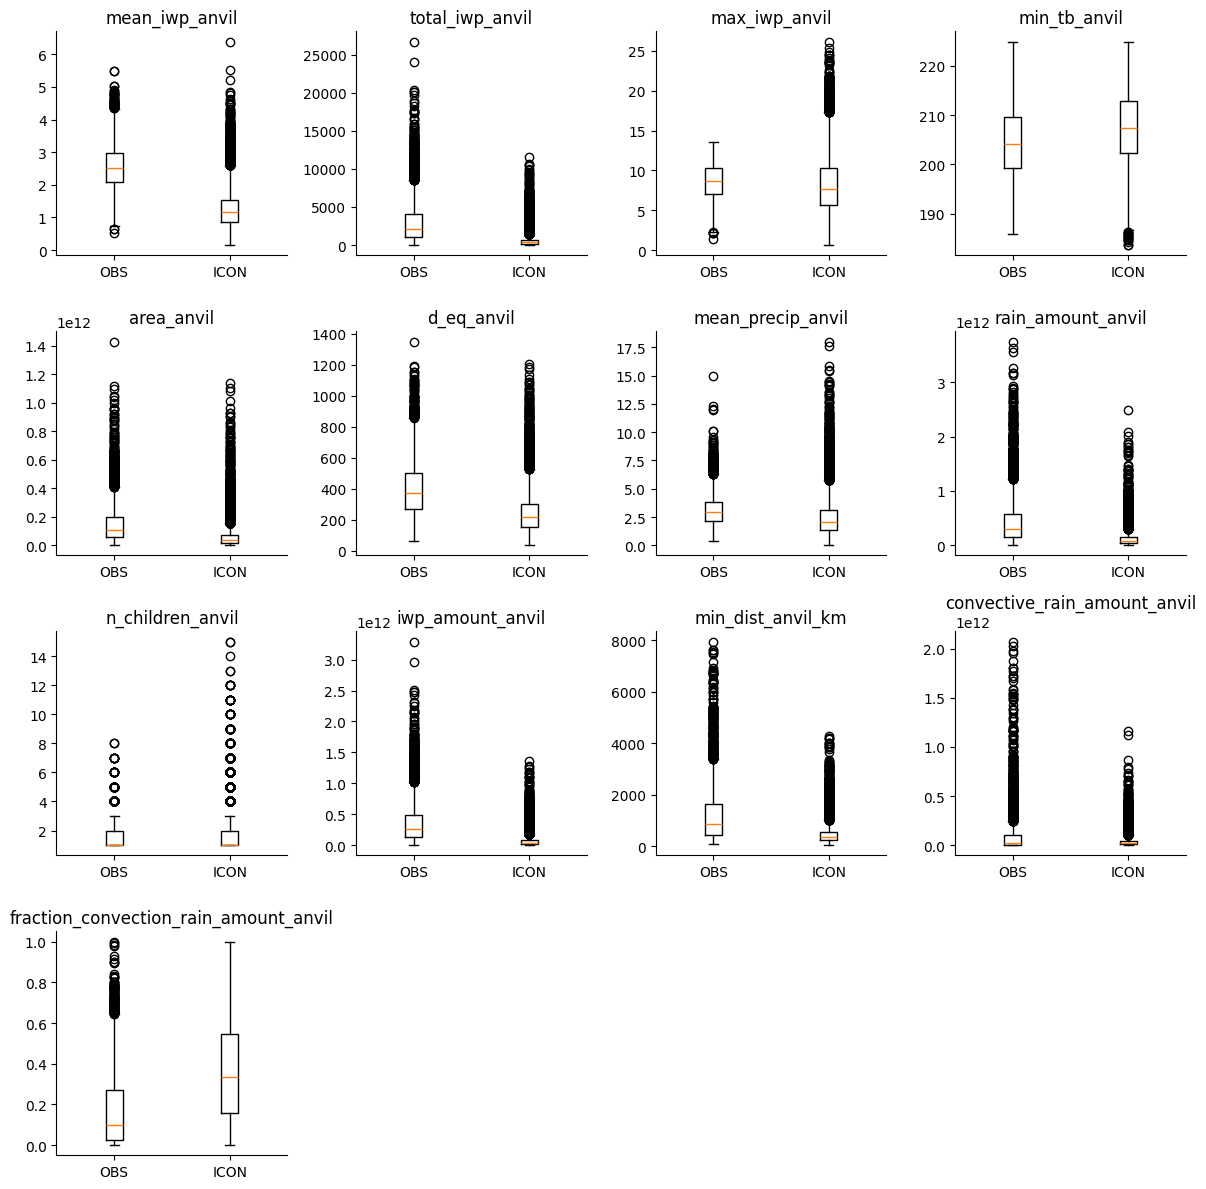

In [9]:
quick_boxplots(anvilfeatures,vars_not_plot = ["time","num_anvil","feature_anvil"])
plt.show()

# cell feature

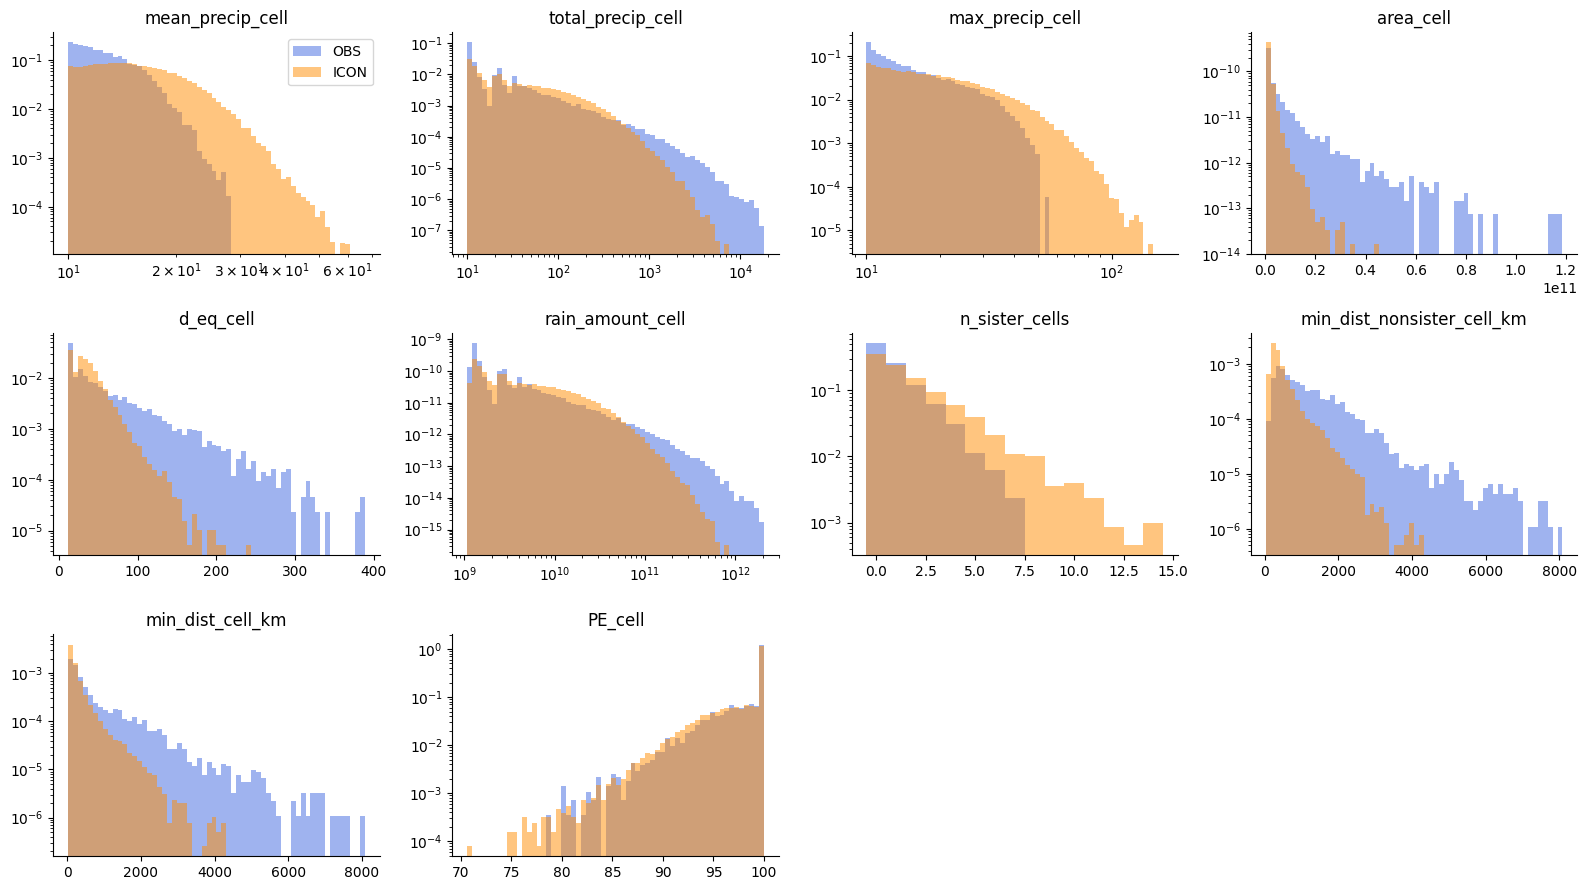

In [10]:
quick_histograms(cellfeatures, vars_not_plot = ["time","num_cell","feature", "time_track"])
plt.savefig(os.path.join(savedir,"cellfeatures_hist.pdf"))
plt.show()

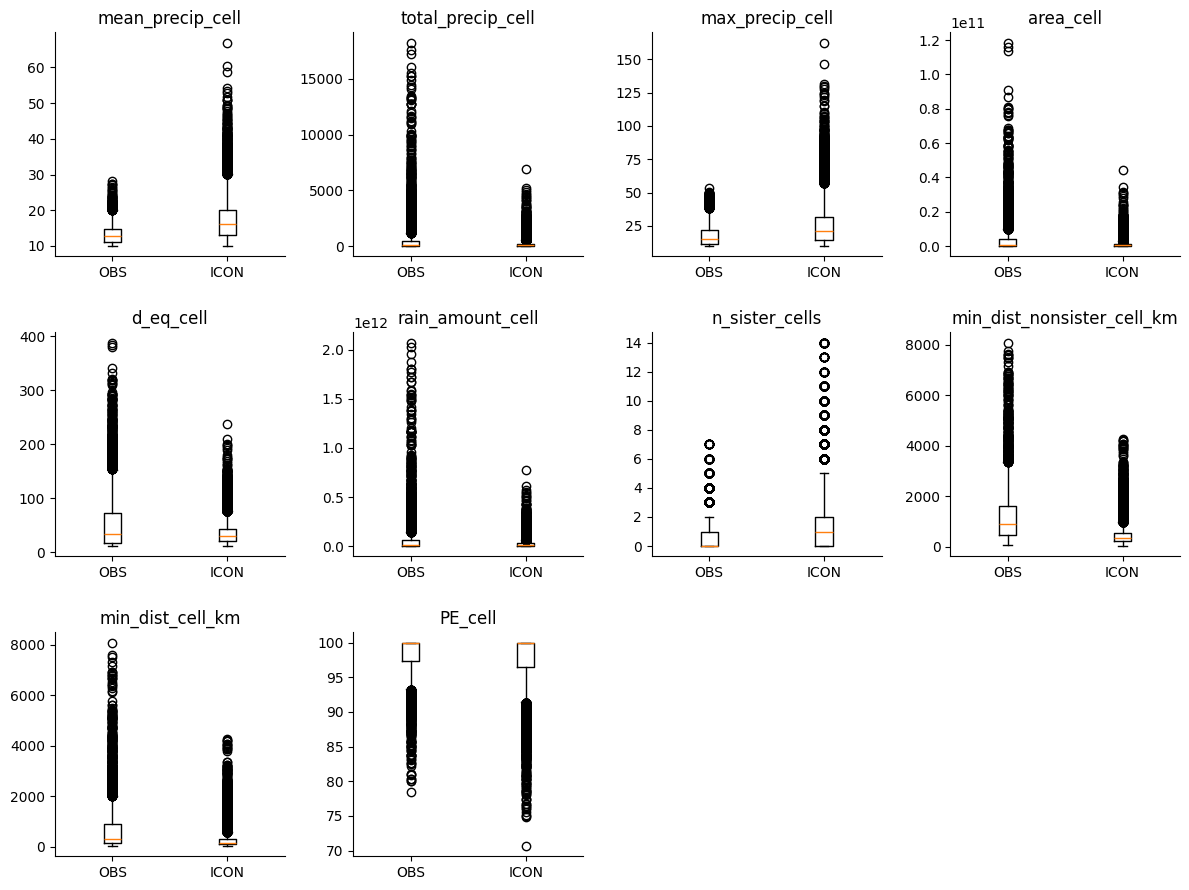

In [11]:
quick_boxplots(cellfeatures, vars_not_plot = ["time","num_cell","feature", "time_track"])
plt.show()

Fraction of anvil-timesteps with exactly one cell: 0.357


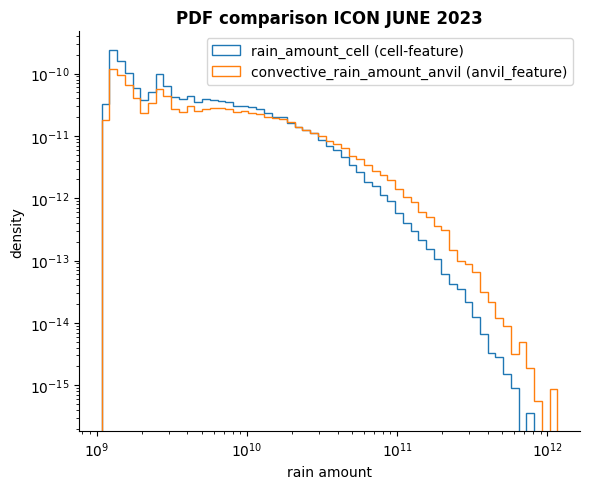

In [12]:
import numpy as np
import matplotlib.pyplot as plt

Tracks_yr = cellfeatures["ICON"]["JUNE"]
anvil_yr = anvilfeatures["ICON"]["JUNE"]

# --- 1. fraction of anvils with exactly one cell (trivial identity case) ---
frac_single = (Tracks_yr["n_sister_cells"] == 0).mean()
print(f"Fraction of anvil-timesteps with exactly one cell: {frac_single:.3f}")


fig, axes = plt.subplots(1, 1, figsize=(6, 5))

# scatter: sum vs max, log-log, with 1:1 line

# --- 4. PDF overlay: rain_amount_cell (all cells) vs convective_rain_amount_anvil ---
ax = axes
bins = np.logspace(
    np.log10(min(Tracks_yr["rain_amount_cell"].min(), anvil_yr["convective_rain_amount_anvil"].min())+1e-6),
    np.log10(max(Tracks_yr["rain_amount_cell"].max(), anvil_yr["convective_rain_amount_anvil"].max())),
    60
)
ax.hist(Tracks_yr["rain_amount_cell"], bins=bins, density=True, histtype="step", label="rain_amount_cell (cell-feature)")
ax.hist(anvil_yr["convective_rain_amount_anvil"], bins=bins, density=True, histtype="step", label="convective_rain_amount_anvil (anvil_feature)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("rain amount")
ax.set_ylabel("density")
ax.legend()
ax.set_title("PDF comparison ICON JUNE 2023", fontweight = "bold")
sns.despine()
plt.tight_layout()
plt.show()




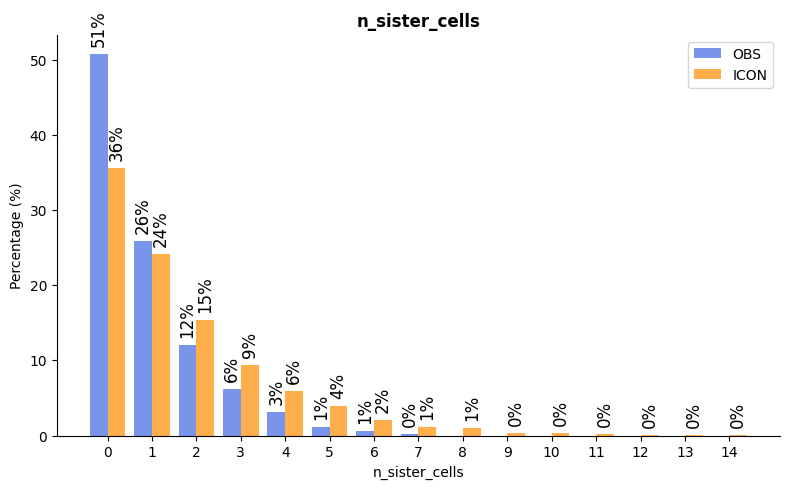

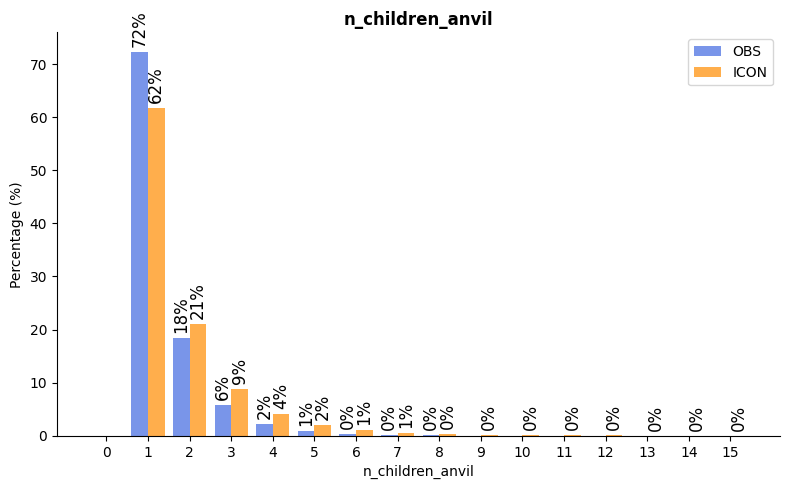

In [13]:
def plot_n_sister_cells(ds, var="n_sister_cells", month="JUNE", as_percent=True):
    obs_vals = ds["OBS"][month][var].dropna()
    icon_vals = ds["ICON"][month][var].dropna()

    # shared integer bins across both datasets
    combined = pd.concat([obs_vals, icon_vals])
    max_val = int(combined.max())
    categories = np.arange(0, max_val + 1)

    obs_counts = obs_vals.value_counts(normalize=as_percent).reindex(categories, fill_value=0)
    icon_counts = icon_vals.value_counts(normalize=as_percent).reindex(categories, fill_value=0)

    if as_percent:
        obs_counts *= 100
        icon_counts *= 100

    x = np.arange(len(categories))
    width = 0.4

    fig, ax = plt.subplots(figsize=(8, 5))
    bars_obs = ax.bar(x - width/2, obs_counts.values, width, label="OBS", color="royalblue", alpha=0.7)
    bars_icon = ax.bar(x + width/2, icon_counts.values, width, label="ICON", color="darkorange", alpha=0.7)

    # % labels on top of each bar
    for bars in (bars_obs, bars_icon):
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                ax.text(bar.get_x() + bar.get_width()/2, height +1,
                         f"{height:.0f}%", ha="center", va="bottom", fontsize=12, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.set_xlabel(var)
    ax.set_ylabel("Percentage (%)" if as_percent else "Count")
    ax.set_title(var, fontweight = "bold")
    #ax.set_yscale("log")
    ax.grid(False)
    ax.legend()

    fig.tight_layout()
    sns.despine()
    return fig
fig = plot_n_sister_cells(cellfeatures)
fig = plot_n_sister_cells(anvilfeatures, "n_children_anvil")

# separte by mulit vs single cell

In [14]:
# --- 5. quantify how close sum is to max, split by whether anvil has sisters ---
Tracks_yr["is_multi_cell"] = Tracks_yr["n_sister_cells"] > 0


# domain


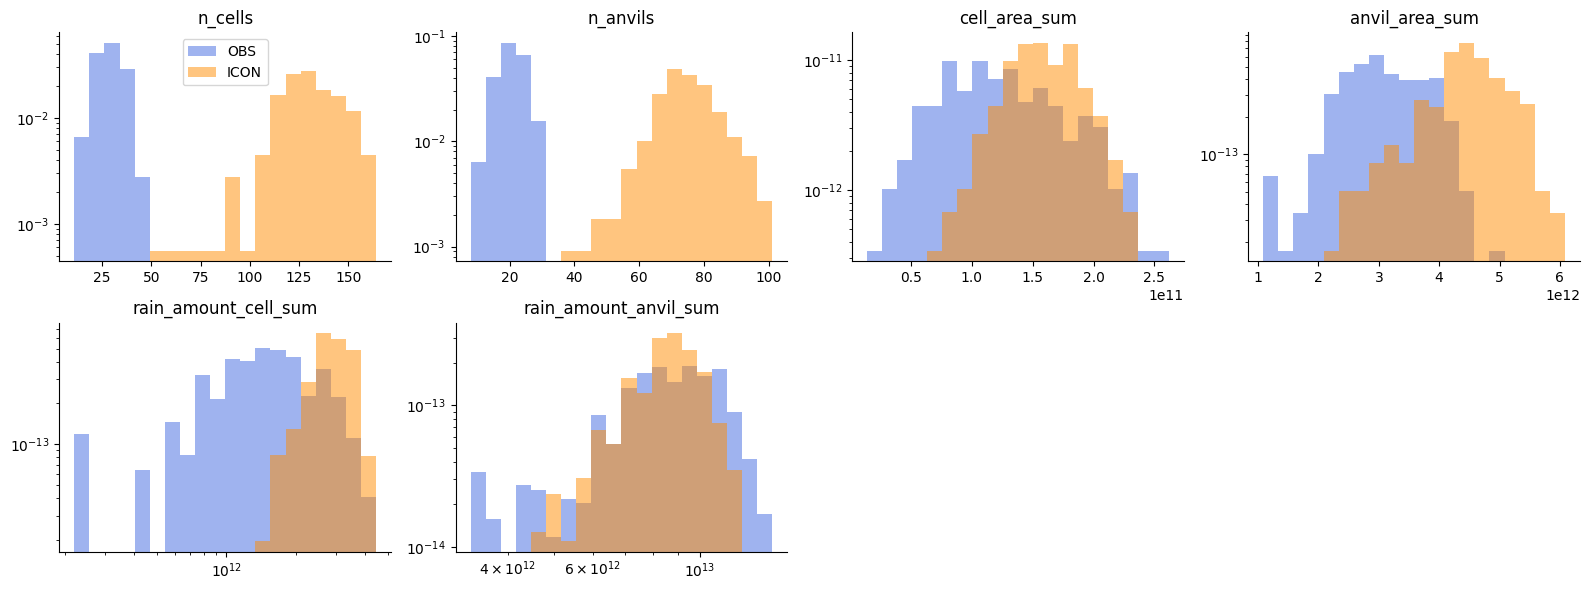

In [23]:
quick_histograms(domain, nbins = 20)
#plt.savefig(os.path.join(savedir,"domain_hist.pdf"))
plt.show()

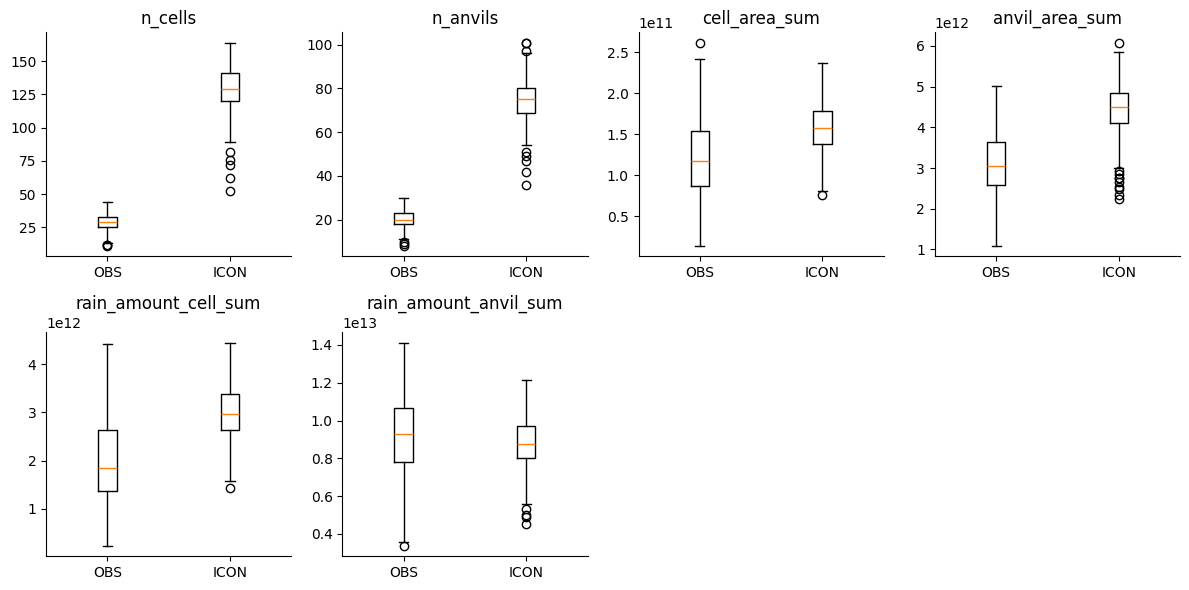

In [22]:
quick_boxplots(domain, vars_not_plot = ["time","feature"])
plt.show()